<a href="https://colab.research.google.com/github/jeniferGoncalvesDaSilvaDev/graph-analysis-classes/blob/main/graph_analysis_classes_path_algorithms_graph_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Path algoritms: Djasktra Algorithm, with python lib: NetworkX

Installing the lib

In [1]:
!pip install networkx

Djasktra Algorithm, alow only positive weight, compare adjacent edges with less cost and storage distance with less sum of costs from weight

In [3]:
import networkx as nx
#create a Graph-G and import the lib network as nx and call the Djasktra algorithm

G = nx.DiGraph()
#add the edges with vertices named S,A,B,C,T and the weights, for example, S to A, cost 4, with a tuple list
#the first param is the origin is the origin, second param is the target and the tird param is the weight
G.add_weighted_edges_from([
    ("S", "A", 4),
    ("S", "B", 1),
    ("A", "C", 1),
    ("B", "C", 5),
    ("C", "T", 1),
])
#Made the comparation, taking the less sum of costs and storage in distance D(C(P)). D-distance,  Sum of Costs from adjacents edges, P-Path(v0, v1...vk), vk-vertices
#In this de origin, is the vertice S(0,0) and the target is the vertice T, the less path is S-A-C-T, S to A to C to T
cost, path = nx.single_source_dijkstra(
    G,
    source="S",
    target="T",
    weight="weight",
)

print("Total cost of less path:", cost)
print("The less path:", path)

Total cost of less path: 6
The less path: ['S', 'A', 'C', 'T']


Bellman Ford Algoritm, allows negative weight, whitch is a better solution than Djasktra Algoritm, that algoritm, run V-1 edges whitch is a advantage, because allow multiple solutions.

Shortest distances:
S: 0
A: 4
B: 2
C: 5

Shortest paths:
S -> S: S
S -> A: S -> A
S -> B: S -> A -> B
S -> C: S -> A -> B -> C


/tmp/ipykernel_334/71571565.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


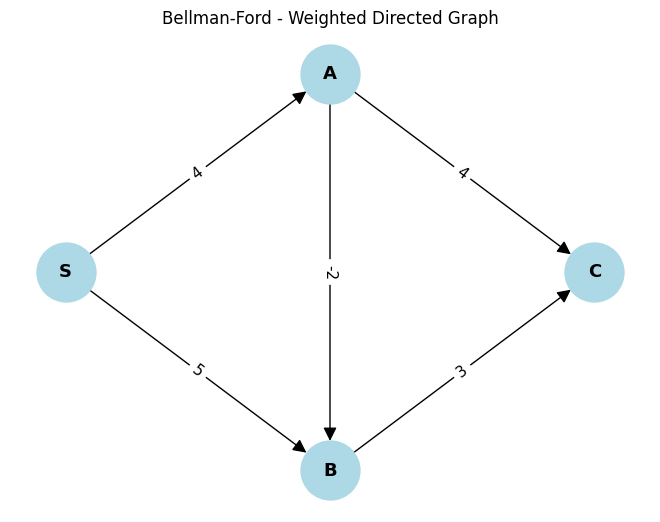

In [4]:

import networkx as nx
import matplotlib.pyplot as plt

# 1. Create a directed graph
G = nx.DiGraph()

# 2. Add weighted edges
edges = [
    ("S", "A", 4),
    ("S", "B", 5),
    ("A", "B", -2),
    ("A", "C", 4),
    ("B", "C", 3),
]

G.add_weighted_edges_from(edges)

# 3. Define the source vertex
source = "S"

try:
    # 4. Run the Bellman-Ford algorithm
    distances, paths = nx.single_source_bellman_ford(
        G,
        source=source,
        weight="weight"
    )

    # 5. Print shortest distances
    print("Shortest distances:")

    for vertex, distance in distances.items():
        print(f"{vertex}: {distance}")

    # 6. Print shortest paths
    print("\nShortest paths:")

    for vertex, path in paths.items():
        print(f"{source} -> {vertex}: {' -> '.join(path)}")

    # 7. Visualize the graph
    pos = {
        "S": (0, 1),
        "A": (1, 2),
        "B": (1, 0),
        "C": (2, 1),
    }

    edge_weights = nx.get_edge_attributes(G, "weight")

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_color="lightblue",
        node_size=1800,
        font_size=13,
        font_weight="bold",
        arrows=True,
        arrowsize=20
    )

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_weights,
        font_size=11
    )

    plt.title("Bellman-Ford - Weighted Directed Graph")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

except nx.NetworkXUnbounded:
    # Handle reachable negative-weight cycles
    print(
        "Error: A reachable negative-weight cycle was detected. "
        "Shortest paths are not well-defined."
    )
